<a href="https://colab.research.google.com/github/julienessan/Gomycode_Cours_Data_Sciences/blob/main/Checkpoint_R%C3%A9seau_de_neurones.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Checkpoint: Réseau de neurones simple et explication

**Objectif** :
Implémenter et comprendre les composants d’un réseau de neurones de base.
Apprendre comment un réseau de neurones simple traite les entrées et ajuste les poids lors de l’entraînement.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Étape 1 : les données (XOR)


In [3]:
X = np.array([[0, 0],
              [0, 1],
              [1, 0],
              [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

print("X :", X.shape)
print("y :", y.shape)

X : (4, 2)
y : (4, 1)


## Étape 2 : architecture et initialisation des poids


In [4]:
n_entree, n_cachee, n_sortie = 2, 4, 1

def initialiser():
    return {
        "W1": np.random.randn(n_entree, n_cachee) * 0.5,  # (2, 4)
        "b1": np.zeros((1, n_cachee)),                    # (1, 4)
        "W2": np.random.randn(n_cachee, n_sortie) * 0.5,  # (4, 1)
        "b2": np.zeros((1, n_sortie)),                    # (1, 1)
    }

params = initialiser()

def resume_modele(p):
    p1 = p["W1"].size + p["b1"].size
    p2 = p["W2"].size + p["b2"].size
    print(f"{'Couche':<20}{'Forme des poids':<18}{'Paramètres':>10}")
    print("-" * 48)
    print(f"{'Entrée':<20}{'-':<18}{0:>10}")
    print(f"{'Cachée (tanh)':<20}{str(p['W1'].shape) + ' + ' + str(p['b1'].shape):<18}{p1:>10}")
    print(f"{'Sortie (sigmoïde)':<20}{str(p['W2'].shape) + ' + ' + str(p['b2'].shape):<18}{p2:>10}")
    print("-" * 48)
    print(f"{'Total':<38}{p1 + p2:>10}")

resume_modele(params)

Couche              Forme des poids   Paramètres
------------------------------------------------
Entrée              -                          0
Cachée (tanh)       (2, 4) + (1, 4)           12
Sortie (sigmoïde)   (4, 1) + (1, 1)            5
------------------------------------------------
Total                                         17


## Étape 3 : fonctions d'activation

- `tanh` (couche cachée) : sortie entre -1 et 1, centrée sur zéro, ce qui aide l'apprentissage.
- `sigmoïde` (sortie) : valeur entre 0 et 1, lue comme la probabilité de la classe 1.

In [5]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

def tanh(z):
    return np.tanh(z)

## Étape 4 : passage avant (forward pass)

Chaque couche fait une somme pondérée plus un biais, puis applique son activation:

In [6]:
def forward(X, p):
    Z1 = X @ p["W1"] + p["b1"]
    A1 = tanh(Z1)
    Z2 = A1 @ p["W2"] + p["b2"]
    A2 = sigmoide(Z2)
    return Z1, A1, Z2, A2

## Étape 5 : fonction de perte

Entropie croisée binaire :


In [7]:
def perte_bce(y, y_pred):
    eps = 1e-8
    return -np.mean(y * np.log(y_pred + eps) + (1 - y) * np.log(1 - y_pred + eps))

## Étape 6 : rétropropagation (backpropagation)

On remonte de la sortie vers l'entrée avec la règle de dérivation en chaîne.

In [8]:
def backward(X, y, p, A1, A2):
    m = X.shape[0]
    dZ2 = A2 - y
    dW2 = A1.T @ dZ2 / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m
    dA1 = dZ2 @ p["W2"].T
    dZ1 = dA1 * (1 - A1 ** 2)
    dW1 = X.T @ dZ1 / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m
    return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

def mettre_a_jour(p, grads, lr):
    for cle in p:
        p[cle] -= lr * grads[cle]

## Étape 7 : une époque décomposée à la main

Avant de lancer la boucle, on observe une seule itération : passage avant, perte, gradients, puis mise à jour des poids.


In [9]:
taux_apprentissage = 0.5

Z1, A1, Z2, A2 = forward(X, params)
print("Passage avant, probabilités A2 :", np.round(A2.ravel(), 4))

perte = perte_bce(y, A2)
print(f"Perte BCE : {perte:.4f}")

grads = backward(X, y, params, A1, A2)
print("Gradient dW2 :", np.round(grads["W2"].ravel(), 4))

print("W2 avant mise à jour :", np.round(params["W2"].ravel(), 4))
mettre_a_jour(params, grads, taux_apprentissage)
print("W2 après mise à jour :", np.round(params["W2"].ravel(), 4))

Passage avant, probabilités A2 : [0.5    0.4398 0.4261 0.3876]
Perte BCE : 0.7145
Gradient dW2 : [-0.0059  0.0084 -0.059  -0.0643]
W2 avant mise à jour : [-0.2347  0.2713 -0.2317 -0.2329]
W2 après mise à jour : [-0.2318  0.2671 -0.2022 -0.2007]


## Étape 8 : boucle d'entraînement

On répète les quatre opérations 2000 fois. La perte est affichée toutes les 200 époques.

In [10]:
epoques = 2000
historique = [perte]  # on garde la perte de l'époque 1 calculée plus haut

for epoque in range(2, epoques + 1):
    Z1, A1, Z2, A2 = forward(X, params)
    perte = perte_bce(y, A2)
    historique.append(perte)
    grads = backward(X, y, params, A1, A2)
    mettre_a_jour(params, grads, taux_apprentissage)

for e in [1] + list(range(200, epoques + 1, 200)):
    print(f"Époque {e:>5} | perte = {historique[e - 1]:.4f}")

Époque     1 | perte = 0.7145
Époque   200 | perte = 0.1979
Époque   400 | perte = 0.0268
Époque   600 | perte = 0.0130
Époque   800 | perte = 0.0085
Époque  1000 | perte = 0.0063
Époque  1200 | perte = 0.0050
Époque  1400 | perte = 0.0041
Époque  1600 | perte = 0.0035
Époque  1800 | perte = 0.0031
Époque  2000 | perte = 0.0027


## Étape 9 : courbe de la perte

La grosse chute arrive entre 200 et 400 époques, quand les neurones cachés trouvent une représentation qui rend XOR séparable.

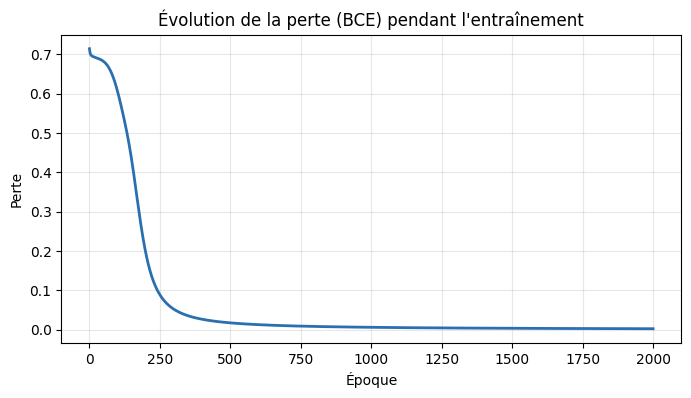

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(historique) + 1), historique, color="#2a6fb0", linewidth=2)
plt.title("Évolution de la perte (BCE) pendant l'entraînement")
plt.xlabel("Époque")
plt.ylabel("Perte")
plt.grid(alpha=0.3)
plt.show()

## Étape 10 : prédictions finales

On refait un passage avant avec les poids appris et on applique un seuil à 0,5.

In [12]:
_, _, _, A2 = forward(X, params)
for entree, proba, cible in zip(X, A2.ravel(), y.ravel()):
    print(f"Entrée {entree.astype(int)} -> proba = {proba:.4f} -> classe {int(proba >= 0.5)} (attendu {int(cible)})")

precision = np.mean((A2 >= 0.5).astype(int) == y)
print(f"\nPrécision : {precision * 100:.0f} %")

Entrée [0 0] -> proba = 0.0003 -> classe 0 (attendu 0)
Entrée [0 1] -> proba = 0.9970 -> classe 1 (attendu 1)
Entrée [1 0] -> proba = 0.9969 -> classe 1 (attendu 1)
Entrée [1 1] -> proba = 0.0045 -> classe 0 (attendu 0)

Précision : 100 %


### Tester un exemple


In [14]:
test = np.array([[1, 0]], dtype=float)
_, _, _, p = forward(test, params)
print(f"Exemple {test.astype(int).ravel()} -> proba = {p[0, 0]:.4f} -> classe {int(p[0, 0] >= 0.5)}")

Exemple [1 0] -> proba = 0.9969 -> classe 1
